In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
DATA_PATH = "../data/lending_club.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [5]:
loan_df = df.copy()

print("Working dataframe created.")

Working dataframe created.


In [6]:
print("Dataset Shape:")
print(loan_df.shape)

print("\nColumn Names:")
print(loan_df.columns.tolist())

print("\nFirst 5 Rows:")
display(loan_df.head())

Dataset Shape:
(9578, 14)

Column Names:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid']

First 5 Rows:


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [7]:
print("Data Types:")
display(loan_df.dtypes)

Data Types:


credit.policy          int64
purpose                  str
int.rate             float64
installment          float64
log.annual.inc       float64
dti                  float64
fico                   int64
days.with.cr.line    float64
revol.bal              int64
revol.util           float64
inq.last.6mths         int64
delinq.2yrs            int64
pub.rec                int64
not.fully.paid         int64
dtype: object

In [8]:
print("Missing Values:")
display(loan_df.isnull().sum())

Missing Values:


credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64

In [9]:
TARGET = "not.fully.paid"

if TARGET in loan_df.columns:
    print(f"Target variable '{TARGET}' found successfully.")
else:
    print(f"WARNING: Target variable '{TARGET}' was not found.")
    print("Available columns:")
    print(loan_df.columns.tolist())

Target variable 'not.fully.paid' found successfully.


In [10]:
if TARGET in loan_df.columns:
    print("Target variable distribution:")
    display(loan_df[TARGET].value_counts())

    print("\nTarget variable proportions:")
    display(loan_df[TARGET].value_counts(normalize=True))

Target variable distribution:


not.fully.paid
0    8045
1    1533
Name: count, dtype: int64


Target variable proportions:


not.fully.paid
0    0.839946
1    0.160054
Name: proportion, dtype: float64

In [12]:
print(f"Dataset shape       : {loan_df.shape}")
print(f"Number of features  : {loan_df.shape[1] - 1}")
print(f"Target variable     : {TARGET}")
print(f"Missing values      : {loan_df.isnull().sum().sum()}")

print("\nDataset is ready for Phase 1.")

Dataset shape       : (9578, 14)
Number of features  : 13
Target variable     : not.fully.paid
Missing values      : 0

Dataset is ready for Phase 1.


In [13]:
categorical_columns = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['purpose']


C:\Users\SATTIE\AppData\Local\Temp\ipykernel_18440\232443931.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()


In [14]:
for column in categorical_columns:
    print(f"\n{column} unique values:")
    print(loan_df[column].unique())

    print(f"\n{column} value counts:")
    print(loan_df[column].value_counts())


purpose unique values:
<StringArray>
['debt_consolidation',        'credit_card',          'all_other',
   'home_improvement',     'small_business',     'major_purchase',
        'educational']
Length: 7, dtype: str

purpose value counts:
purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64


In [15]:
# ------------------------------------------------------------
# 3. Convert categorical values into numerical values
#    using one-hot encoding
# ------------------------------------------------------------

loan_df_transformed = pd.get_dummies(
    loan_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Categorical transformation completed.")

Categorical transformation completed.


In [16]:
# ------------------------------------------------------------
# 4. Display the transformed dataset
# ------------------------------------------------------------

print("Transformed dataset shape:")
print(loan_df_transformed.shape)

print("\nTransformed columns:")
print(loan_df_transformed.columns.tolist())

print("\nFirst 5 rows:")
display(loan_df_transformed.head())

Transformed dataset shape:
(9578, 19)

Transformed columns:
['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']

First 5 rows:


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,1,0,0,0,0,0


In [17]:
# ------------------------------------------------------------
# 4. Display the transformed dataset
# ------------------------------------------------------------

print("Transformed dataset shape:")
print(loan_df_transformed.shape)

print("\nTransformed columns:")
print(loan_df_transformed.columns.tolist())

print("\nFirst 5 rows:")
display(loan_df_transformed.head())

Transformed dataset shape:
(9578, 19)

Transformed columns:
['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']

First 5 rows:


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,1,0,0,0,0,0


In [18]:
# ------------------------------------------------------------
# 5. Verify that categorical columns are no longer present
# ------------------------------------------------------------

remaining_categorical_columns = loan_df_transformed.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Remaining categorical columns:")
print(remaining_categorical_columns)

Remaining categorical columns:
[]


In [19]:
# ------------------------------------------------------------
# 6. Verify all feature data types
# ------------------------------------------------------------

print("Data types after feature transformation:")
display(loan_df_transformed.dtypes)

Data types after feature transformation:


credit.policy                   int64
int.rate                      float64
installment                   float64
log.annual.inc                float64
dti                           float64
fico                            int64
days.with.cr.line             float64
revol.bal                       int64
revol.util                    float64
inq.last.6mths                  int64
delinq.2yrs                     int64
pub.rec                         int64
not.fully.paid                  int64
purpose_credit_card             int64
purpose_debt_consolidation      int64
purpose_educational             int64
purpose_home_improvement        int64
purpose_major_purchase          int64
purpose_small_business          int64
dtype: object

In [20]:
# ------------------------------------------------------------
# 7. Verify target variable is unchanged
# ------------------------------------------------------------

print("Target variable distribution after transformation:")
display(loan_df_transformed[TARGET].value_counts())

print("\nTarget variable proportions:")
display(loan_df_transformed[TARGET].value_counts(normalize=True))

Target variable distribution after transformation:


not.fully.paid
0    8045
1    1533
Name: count, dtype: int64


Target variable proportions:


not.fully.paid
0    0.839946
1    0.160054
Name: proportion, dtype: float64

In [22]:
# ------------------------------------------------------------
# 8. Replace working dataframe with transformed dataframe
# ------------------------------------------------------------

loan_df = loan_df_transformed.copy()

print(f"Dataset shape after transformation : {loan_df.shape}")
print(f"Target variable                    : {TARGET}")
print(f"Remaining categorical columns      : {loan_df.select_dtypes(include=['object', 'category']).columns.tolist()}")

Dataset shape after transformation : (9578, 19)
Target variable                    : not.fully.paid
Remaining categorical columns      : []


In [23]:
# ============================================================
# PHASE 2 — EXPLORATORY DATA ANALYSIS
# Lending Club Loan Data Analysis
# ============================================================

# ------------------------------------------------------------
# 1. Statistical summary
# ------------------------------------------------------------

print("=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

display(loan_df.describe().T)

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
credit.policy,9578.0,0.804970,0.396245,0.000000,1.000000,1.000000,1.000000,1.000000e+00
int.rate,9578.0,0.122640,0.026847,0.060000,0.103900,0.122100,0.140700,2.164000e-01
installment,9578.0,319.089413,207.071301,15.670000,163.770000,268.950000,432.762500,9.401400e+02
log.annual.inc,9578.0,10.932117,0.614813,7.547502,10.558414,10.928884,11.291293,1.452835e+01
dti,9578.0,12.606679,6.883970,0.000000,7.212500,12.665000,17.950000,2.996000e+01
fico,9578.0,710.846314,37.970537,612.000000,682.000000,707.000000,737.000000,8.270000e+02
days.with.cr.line,9578.0,4560.767197,2496.930377,178.958333,2820.000000,4139.958333,5730.000000,1.763996e+04
revol.bal,9578.0,16913.963876,33756.189557,0.000000,3187.000000,8596.000000,18249.500000,1.207359e+06
revol.util,9578.0,46.799236,29.014417,0.000000,22.600000,46.300000,70.900000,1.190000e+02
inq.last.6mths,9578.0,1.577469,2.200245,0.000000,0.000000,1.000000,2.000000,3.300000e+01


In [24]:
# ------------------------------------------------------------
# 2. Dataset information
# ------------------------------------------------------------

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print(f"Number of observations : {loan_df.shape[0]}")
print(f"Number of columns     : {loan_df.shape[1]}")

print("\nData types:")
display(loan_df.dtypes)

print("\nMissing values:")
display(loan_df.isnull().sum())

DATASET INFORMATION
Number of observations : 9578
Number of columns     : 19

Data types:


credit.policy                   int64
int.rate                      float64
installment                   float64
log.annual.inc                float64
dti                           float64
fico                            int64
days.with.cr.line             float64
revol.bal                       int64
revol.util                    float64
inq.last.6mths                  int64
delinq.2yrs                     int64
pub.rec                         int64
not.fully.paid                  int64
purpose_credit_card             int64
purpose_debt_consolidation      int64
purpose_educational             int64
purpose_home_improvement        int64
purpose_major_purchase          int64
purpose_small_business          int64
dtype: object


Missing values:


credit.policy                 0
int.rate                      0
installment                   0
log.annual.inc                0
dti                           0
fico                          0
days.with.cr.line             0
revol.bal                     0
revol.util                    0
inq.last.6mths                0
delinq.2yrs                   0
pub.rec                       0
not.fully.paid                0
purpose_credit_card           0
purpose_debt_consolidation    0
purpose_educational           0
purpose_home_improvement      0
purpose_major_purchase        0
purpose_small_business        0
dtype: int64

In [25]:
# ------------------------------------------------------------
# 2. Dataset information
# ------------------------------------------------------------

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print(f"Number of observations : {loan_df.shape[0]}")
print(f"Number of columns     : {loan_df.shape[1]}")

print("\nData types:")
display(loan_df.dtypes)

print("\nMissing values:")
display(loan_df.isnull().sum())

DATASET INFORMATION
Number of observations : 9578
Number of columns     : 19

Data types:


credit.policy                   int64
int.rate                      float64
installment                   float64
log.annual.inc                float64
dti                           float64
fico                            int64
days.with.cr.line             float64
revol.bal                       int64
revol.util                    float64
inq.last.6mths                  int64
delinq.2yrs                     int64
pub.rec                         int64
not.fully.paid                  int64
purpose_credit_card             int64
purpose_debt_consolidation      int64
purpose_educational             int64
purpose_home_improvement        int64
purpose_major_purchase          int64
purpose_small_business          int64
dtype: object


Missing values:


credit.policy                 0
int.rate                      0
installment                   0
log.annual.inc                0
dti                           0
fico                          0
days.with.cr.line             0
revol.bal                     0
revol.util                    0
inq.last.6mths                0
delinq.2yrs                   0
pub.rec                       0
not.fully.paid                0
purpose_credit_card           0
purpose_debt_consolidation    0
purpose_educational           0
purpose_home_improvement      0
purpose_major_purchase        0
purpose_small_business        0
dtype: int64

In [26]:
# ------------------------------------------------------------
# 3. Target variable distribution
# ------------------------------------------------------------

print("=" * 60)
print("LOAN DEFAULT DISTRIBUTION")
print("=" * 60)

target_counts = loan_df[TARGET].value_counts().sort_index()
target_percentages = loan_df[TARGET].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

target_summary.index = ["Not Fully Paid (0)", "Fully Paid (1)"]

display(target_summary)

LOAN DEFAULT DISTRIBUTION


,Count,Percentage
Not Fully Paid (0),8045,83.99
Fully Paid (1),1533,16.01


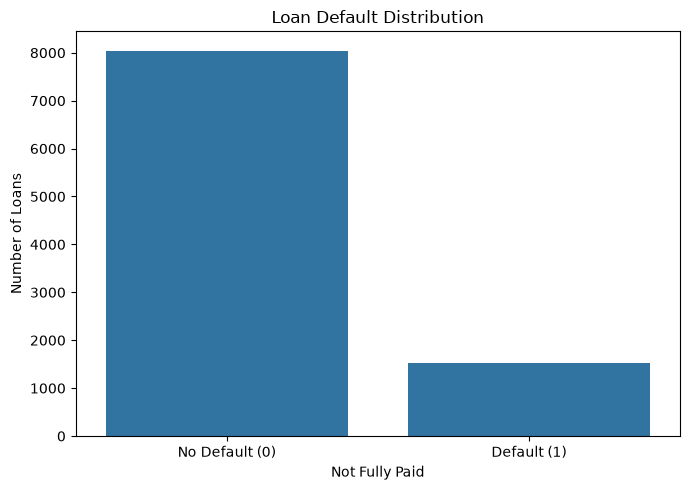

In [27]:
# ------------------------------------------------------------
# 4. Target variable visualization
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    data=loan_df,
    x=TARGET
)

plt.title("Loan Default Distribution")
plt.xlabel("Not Fully Paid")
plt.ylabel("Number of Loans")

plt.xticks(
    [0, 1],
    ["No Default (0)", "Default (1)"]
)

plt.tight_layout()
plt.show()

In [28]:
# ------------------------------------------------------------
# 5. Distribution of numerical features
# ------------------------------------------------------------

numeric_features = loan_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove target from feature list
numeric_features.remove(TARGET)

print("Numerical features:")
print(numeric_features)

Numerical features:
['credit.policy', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']


In [29]:
# ------------------------------------------------------------
# 6. Loan purpose distribution
# ------------------------------------------------------------

purpose_columns = [
    column
    for column in loan_df.columns
    if column.startswith("purpose_")
]

# Reconstruct the purpose category
purpose_data = pd.DataFrame(index=loan_df.index)

purpose_data["purpose"] = "all_other"

for column in purpose_columns:
    category = column.replace("purpose_", "")

    purpose_data.loc[
        loan_df[column] == 1,
        "purpose"
    ] = category

print("Loan purpose distribution:")

purpose_counts = purpose_data["purpose"].value_counts()

display(purpose_counts)

Loan purpose distribution:


purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64

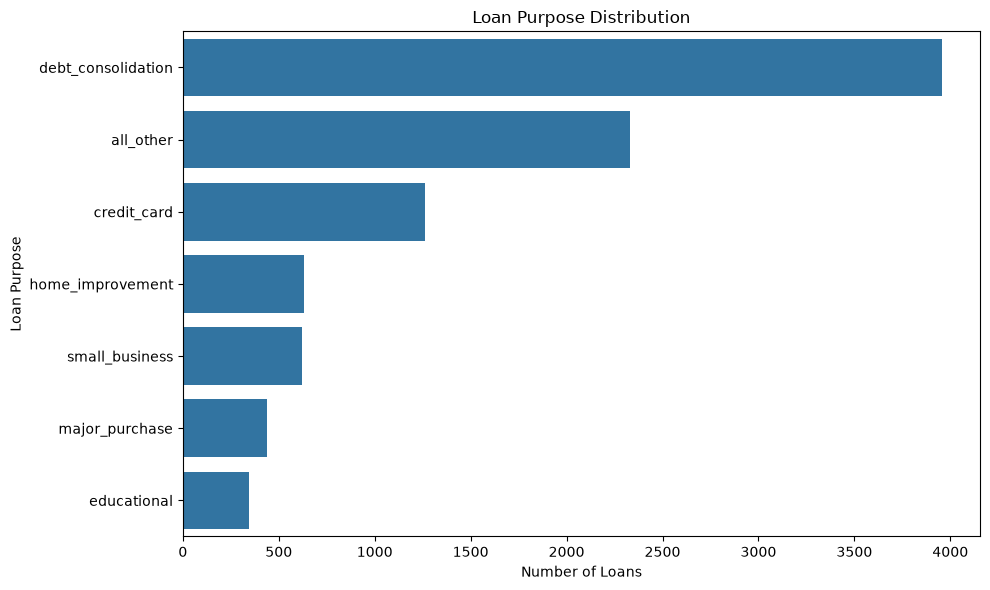

In [30]:
# Visualize loan purpose distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=purpose_data,
    y="purpose",
    order=purpose_counts.index
)

plt.title("Loan Purpose Distribution")
plt.xlabel("Number of Loans")
plt.ylabel("Loan Purpose")

plt.tight_layout()
plt.show()

In [31]:
# ------------------------------------------------------------
# 7. Default rate by loan purpose
# ------------------------------------------------------------

purpose_default = pd.DataFrame({
    "purpose": purpose_data["purpose"],
    TARGET: loan_df[TARGET]
})

default_rate_by_purpose = (
    purpose_default
    .groupby("purpose")[TARGET]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

default_rate_by_purpose.columns = [
    "Total Loans",
    "Defaults",
    "Default Rate"
]

default_rate_by_purpose["Default Rate"] = (
    default_rate_by_purpose["Default Rate"] * 100
).round(2)

print("Default rate by loan purpose:")

display(default_rate_by_purpose)

Default rate by loan purpose:


,Total Loans,Defaults,Default Rate
purpose,,,
small_business,619,172,27.79
educational,343,69,20.12
home_improvement,629,107,17.01
all_other,2331,387,16.60
debt_consolidation,3957,603,15.24
credit_card,1262,146,11.57
major_purchase,437,49,11.21


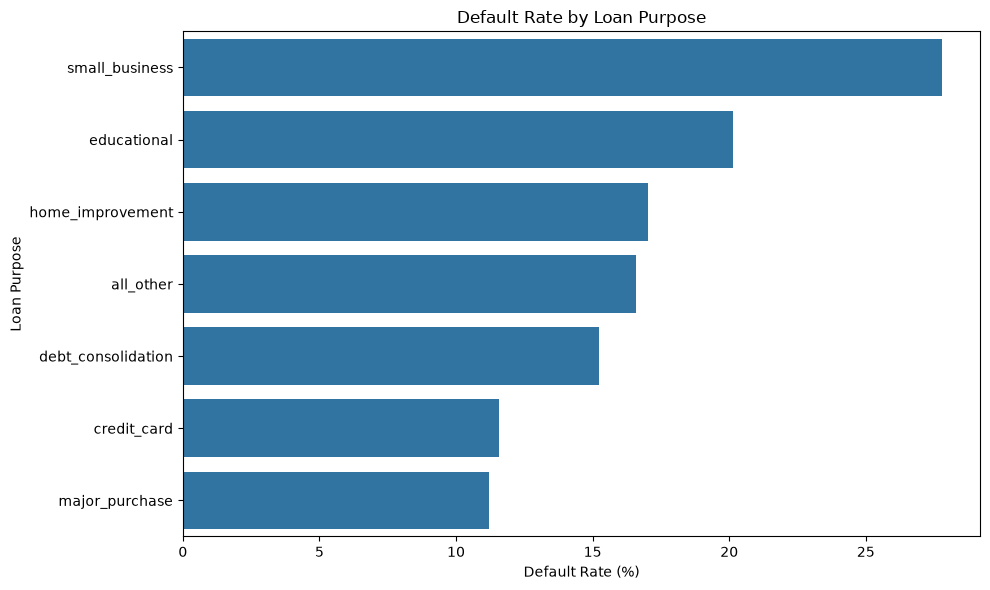

In [32]:
# Visualize default rate by purpose

plt.figure(figsize=(10, 6))

sns.barplot(
    data=default_rate_by_purpose.reset_index(),
    x="Default Rate",
    y="purpose"
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Purpose")

plt.tight_layout()
plt.show()

In [33]:
# ------------------------------------------------------------
# 8. Numerical features vs loan default
# ------------------------------------------------------------

# Select the most relevant numerical credit/financial factors
eda_features = [
    "int.rate",
    "installment",
    "log.annual.inc",
    "dti",
    "fico",
    "revol.util",
    "inq.last.6mths",
    "delinq.2yrs",
    "pub.rec"
]

eda_features = [
    feature for feature in eda_features
    if feature in loan_df.columns
]

print("Numerical factors selected for default comparison:")
print(eda_features)

Numerical factors selected for default comparison:
['int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec']


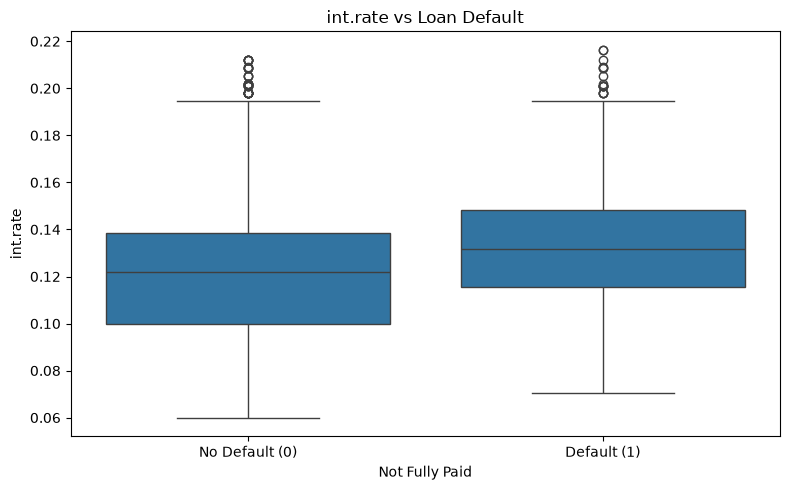

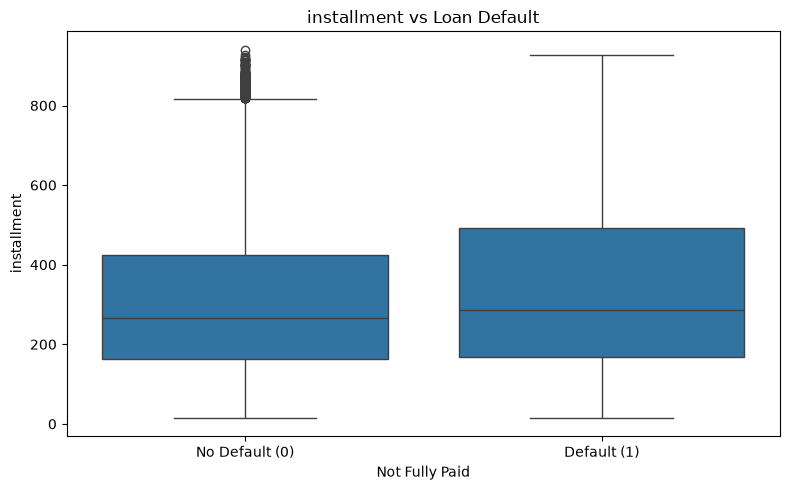

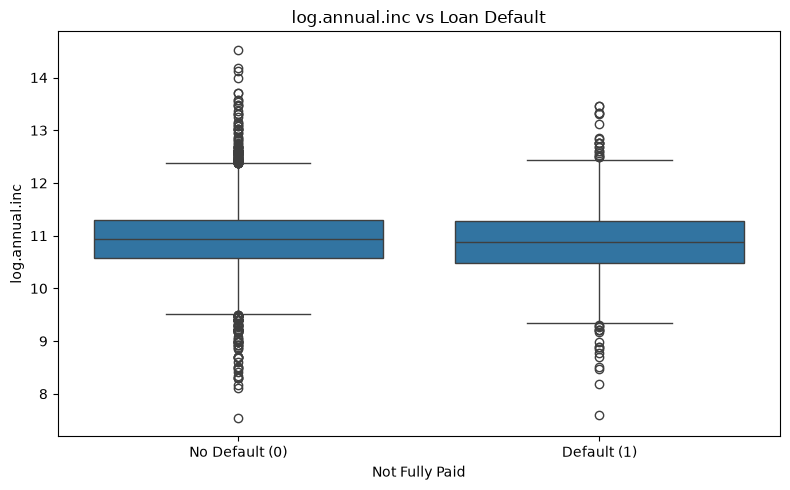

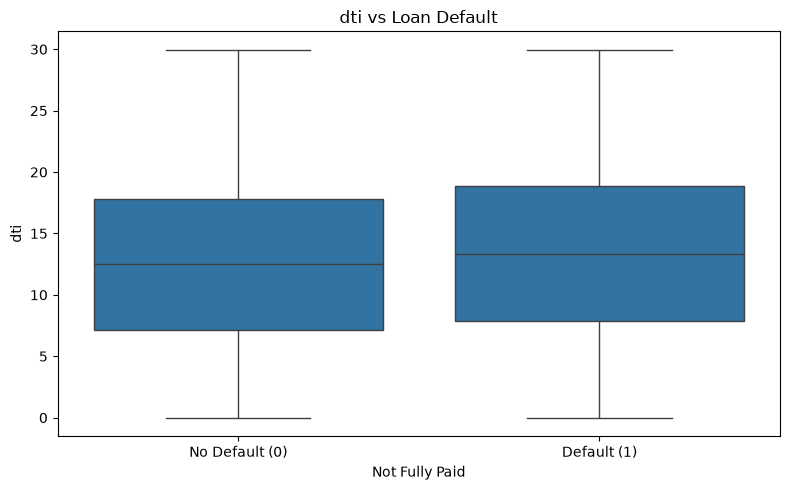

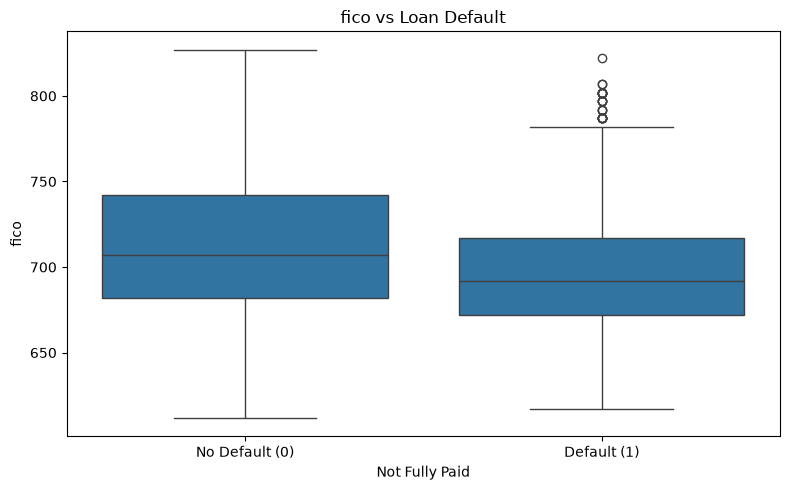

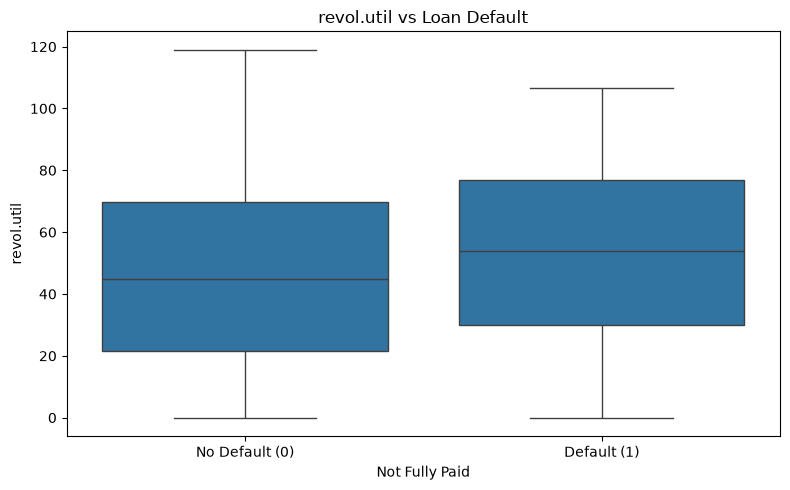

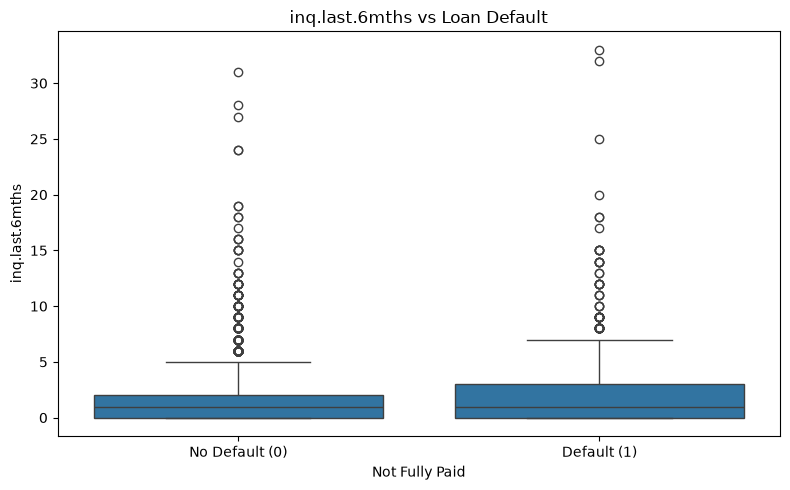

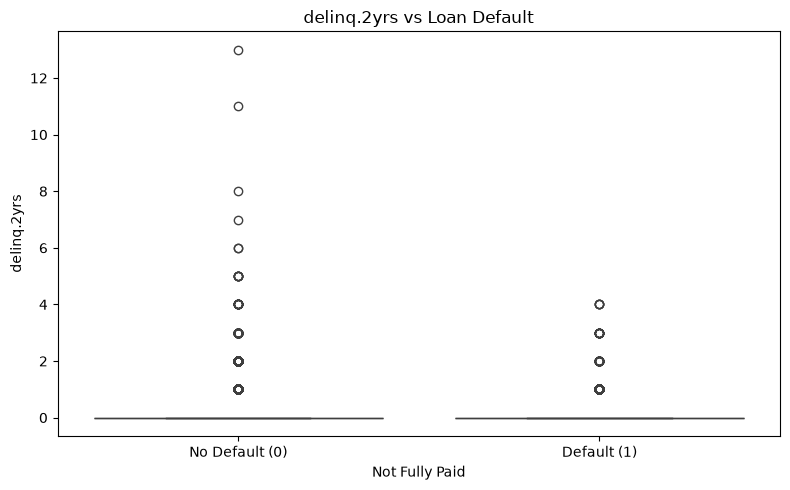

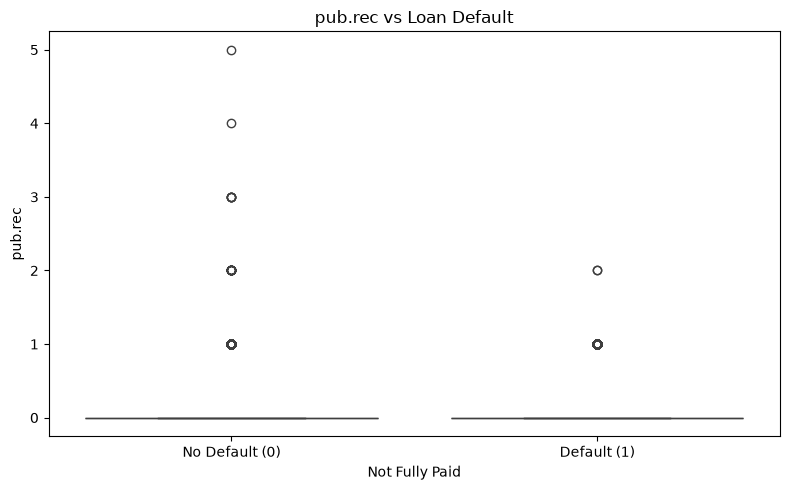

In [34]:
# Compare distributions for each selected numerical feature

for feature in eda_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=loan_df,
        x=TARGET,
        y=feature
    )

    plt.title(f"{feature} vs Loan Default")
    plt.xlabel("Not Fully Paid")
    plt.ylabel(feature)

    plt.xticks(
        [0, 1],
        ["No Default (0)", "Default (1)"]
    )

    plt.tight_layout()
    plt.show()

In [35]:
# ------------------------------------------------------------
# 9. Correlation matrix
# ------------------------------------------------------------

correlation_matrix = loan_df.corr(numeric_only=True)

print("=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

display(correlation_matrix.round(2))

CORRELATION MATRIX


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
credit.policy,1.00,-0.29,0.06,0.03,-0.09,0.35,0.10,-0.19,-0.10,-0.54,-0.08,-0.05,-0.16,0.00,0.02,-0.03,0.01,0.02,-0.00
int.rate,-0.29,1.00,0.28,0.06,0.22,-0.71,-0.12,0.09,0.46,0.20,0.16,0.10,0.16,-0.04,0.12,-0.02,-0.05,-0.07,0.15
installment,0.06,0.28,1.00,0.45,0.05,0.09,0.18,0.23,0.08,-0.01,-0.00,-0.03,0.05,0.00,0.16,-0.09,0.02,-0.08,0.15
log.annual.inc,0.03,0.06,0.45,1.00,-0.05,0.11,0.34,0.37,0.05,0.03,0.03,0.02,-0.03,0.07,-0.03,-0.12,0.12,-0.03,0.09
dti,-0.09,0.22,0.05,-0.05,1.00,-0.24,0.06,0.19,0.34,0.03,-0.02,0.01,0.04,0.08,0.18,-0.04,-0.09,-0.08,-0.07
fico,0.35,-0.71,0.09,0.11,-0.24,1.00,0.26,-0.02,-0.54,-0.19,-0.22,-0.15,-0.15,-0.01,-0.15,-0.01,0.10,0.07,0.06
days.with.cr.line,0.10,-0.12,0.18,0.34,0.06,0.26,1.00,0.23,-0.02,-0.04,0.08,0.07,-0.03,0.05,-0.01,-0.04,0.07,-0.02,0.03
revol.bal,-0.19,0.09,0.23,0.37,0.19,-0.02,0.23,1.00,0.20,0.02,-0.03,-0.03,0.05,0.07,0.01,-0.03,0.00,-0.06,0.08
revol.util,-0.10,0.46,0.08,0.05,0.34,-0.54,-0.02,0.20,1.00,-0.01,-0.04,0.07,0.08,0.09,0.21,-0.05,-0.11,-0.11,-0.06
inq.last.6mths,-0.54,0.20,-0.01,0.03,0.03,-0.19,-0.04,0.02,-0.01,1.00,0.02,0.07,0.15,-0.03,-0.04,0.02,0.04,-0.00,0.04


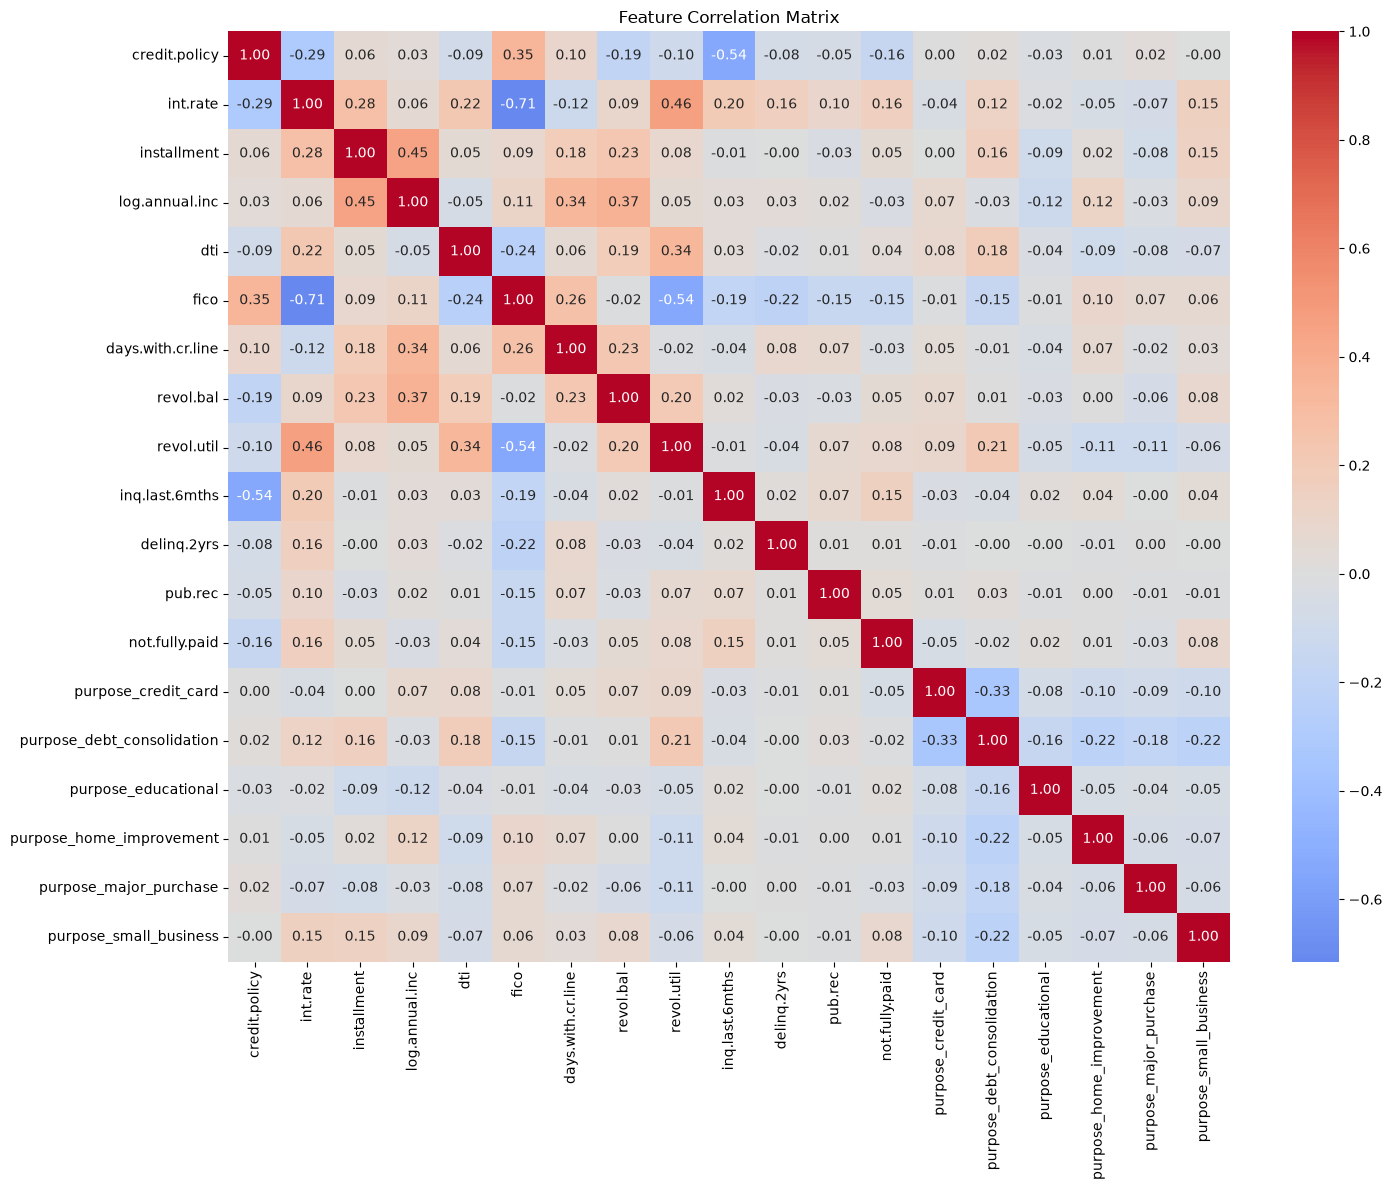

In [36]:
# Visualize correlation matrix

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [37]:
# ------------------------------------------------------------
# 10. Correlation of features with target
# ------------------------------------------------------------

target_correlations = (
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

print("=" * 60)
print("FEATURE CORRELATION WITH TARGET")
print("=" * 60)

display(target_correlations.to_frame("Correlation with Target"))

FEATURE CORRELATION WITH TARGET


,Correlation with Target
int.rate,0.159552
credit.policy,-0.158119
fico,-0.149666
inq.last.6mths,0.149452
purpose_small_business,0.084460
revol.util,0.082088
revol.bal,0.053699
installment,0.049955
pub.rec,0.048634
purpose_credit_card,-0.047136


In [38]:
# ------------------------------------------------------------
# 11. Phase 2 completion summary
# ------------------------------------------------------------

print(f"Observations          : {loan_df.shape[0]}")
print(f"Features/columns      : {loan_df.shape[1]}")
print(f"Missing values        : {loan_df.isnull().sum().sum()}")

Observations          : 9578
Features/columns      : 19
Missing values        : 0


In [39]:
# ============================================================
# PHASE 3 — ADDITIONAL FEATURE ENGINEERING
# Correlation-Based Feature Reduction
# ============================================================

# ------------------------------------------------------------
# 1. Separate features and target
# ------------------------------------------------------------

X = loan_df.drop(columns=[TARGET]).copy()
y = loan_df[TARGET].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget variable:")
print(TARGET)

Features shape: (9578, 18)
Target shape: (9578,)

Target variable:
not.fully.paid


In [40]:
# ------------------------------------------------------------
# 2. Calculate correlation between features
# ------------------------------------------------------------

feature_correlation = X.corr()

print("Feature correlation matrix:")
display(feature_correlation.round(2))

Feature correlation matrix:


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
credit.policy,1.00,-0.29,0.06,0.03,-0.09,0.35,0.10,-0.19,-0.10,-0.54,-0.08,-0.05,0.00,0.02,-0.03,0.01,0.02,-0.00
int.rate,-0.29,1.00,0.28,0.06,0.22,-0.71,-0.12,0.09,0.46,0.20,0.16,0.10,-0.04,0.12,-0.02,-0.05,-0.07,0.15
installment,0.06,0.28,1.00,0.45,0.05,0.09,0.18,0.23,0.08,-0.01,-0.00,-0.03,0.00,0.16,-0.09,0.02,-0.08,0.15
log.annual.inc,0.03,0.06,0.45,1.00,-0.05,0.11,0.34,0.37,0.05,0.03,0.03,0.02,0.07,-0.03,-0.12,0.12,-0.03,0.09
dti,-0.09,0.22,0.05,-0.05,1.00,-0.24,0.06,0.19,0.34,0.03,-0.02,0.01,0.08,0.18,-0.04,-0.09,-0.08,-0.07
fico,0.35,-0.71,0.09,0.11,-0.24,1.00,0.26,-0.02,-0.54,-0.19,-0.22,-0.15,-0.01,-0.15,-0.01,0.10,0.07,0.06
days.with.cr.line,0.10,-0.12,0.18,0.34,0.06,0.26,1.00,0.23,-0.02,-0.04,0.08,0.07,0.05,-0.01,-0.04,0.07,-0.02,0.03
revol.bal,-0.19,0.09,0.23,0.37,0.19,-0.02,0.23,1.00,0.20,0.02,-0.03,-0.03,0.07,0.01,-0.03,0.00,-0.06,0.08
revol.util,-0.10,0.46,0.08,0.05,0.34,-0.54,-0.02,0.20,1.00,-0.01,-0.04,0.07,0.09,0.21,-0.05,-0.11,-0.11,-0.06
inq.last.6mths,-0.54,0.20,-0.01,0.03,0.03,-0.19,-0.04,0.02,-0.01,1.00,0.02,0.07,-0.03,-0.04,0.02,0.04,-0.00,0.04


In [41]:
# ------------------------------------------------------------
# 3. Identify strongly correlated feature pairs
# ------------------------------------------------------------

correlation_threshold = 0.70

# Get the upper triangle of the correlation matrix
upper_triangle = feature_correlation.where(
    np.triu(np.ones(feature_correlation.shape), k=1).astype(bool)
)

strong_correlations = []

for column in upper_triangle.columns:
    for row in upper_triangle.index:
        correlation_value = upper_triangle.loc[row, column]

        if pd.notna(correlation_value) and abs(correlation_value) >= correlation_threshold:
            strong_correlations.append({
                "Feature 1": row,
                "Feature 2": column,
                "Correlation": correlation_value
            })

strong_correlation_df = pd.DataFrame(strong_correlations)

print("=" * 60)
print("STRONGLY CORRELATED FEATURE PAIRS")
print("=" * 60)

if len(strong_correlation_df) > 0:
    display(strong_correlation_df)
else:
    print("No strongly correlated feature pairs found.")

STRONGLY CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Correlation
0,int.rate,fico,-0.714821


In [42]:
# ------------------------------------------------------------
# 4. Remove strongly correlated redundant feature
# ------------------------------------------------------------

features_to_drop = ["int.rate"]

X_reduced = X.drop(columns=features_to_drop)

print("Features removed:")
print(features_to_drop)

print("\nOriginal number of features:", X.shape[1])
print("Remaining number of features:", X_reduced.shape[1])

Features removed:
['int.rate']

Original number of features: 18
Remaining number of features: 17


In [43]:
# ------------------------------------------------------------
# 5. Display final feature set
# ------------------------------------------------------------

print("=" * 60)
print("FINAL FEATURE SET")
print("=" * 60)

print(X_reduced.columns.tolist())

FINAL FEATURE SET
['credit.policy', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']


In [44]:
# ------------------------------------------------------------
# 6. Verify remaining feature correlations
# ------------------------------------------------------------

reduced_correlation = X_reduced.corr()

upper_triangle_reduced = reduced_correlation.where(
    np.triu(np.ones(reduced_correlation.shape), k=1).astype(bool)
)

remaining_strong_correlations = []

for column in upper_triangle_reduced.columns:
    for row in upper_triangle_reduced.index:
        correlation_value = upper_triangle_reduced.loc[row, column]

        if pd.notna(correlation_value) and abs(correlation_value) >= correlation_threshold:
            remaining_strong_correlations.append({
                "Feature 1": row,
                "Feature 2": column,
                "Correlation": correlation_value
            })

remaining_strong_df = pd.DataFrame(remaining_strong_correlations)

print("=" * 60)
print("REMAINING STRONG CORRELATIONS")
print("=" * 60)

if len(remaining_strong_df) > 0:
    display(remaining_strong_df)
else:
    print("No strong feature correlations remain.")

REMAINING STRONG CORRELATIONS
No strong feature correlations remain.


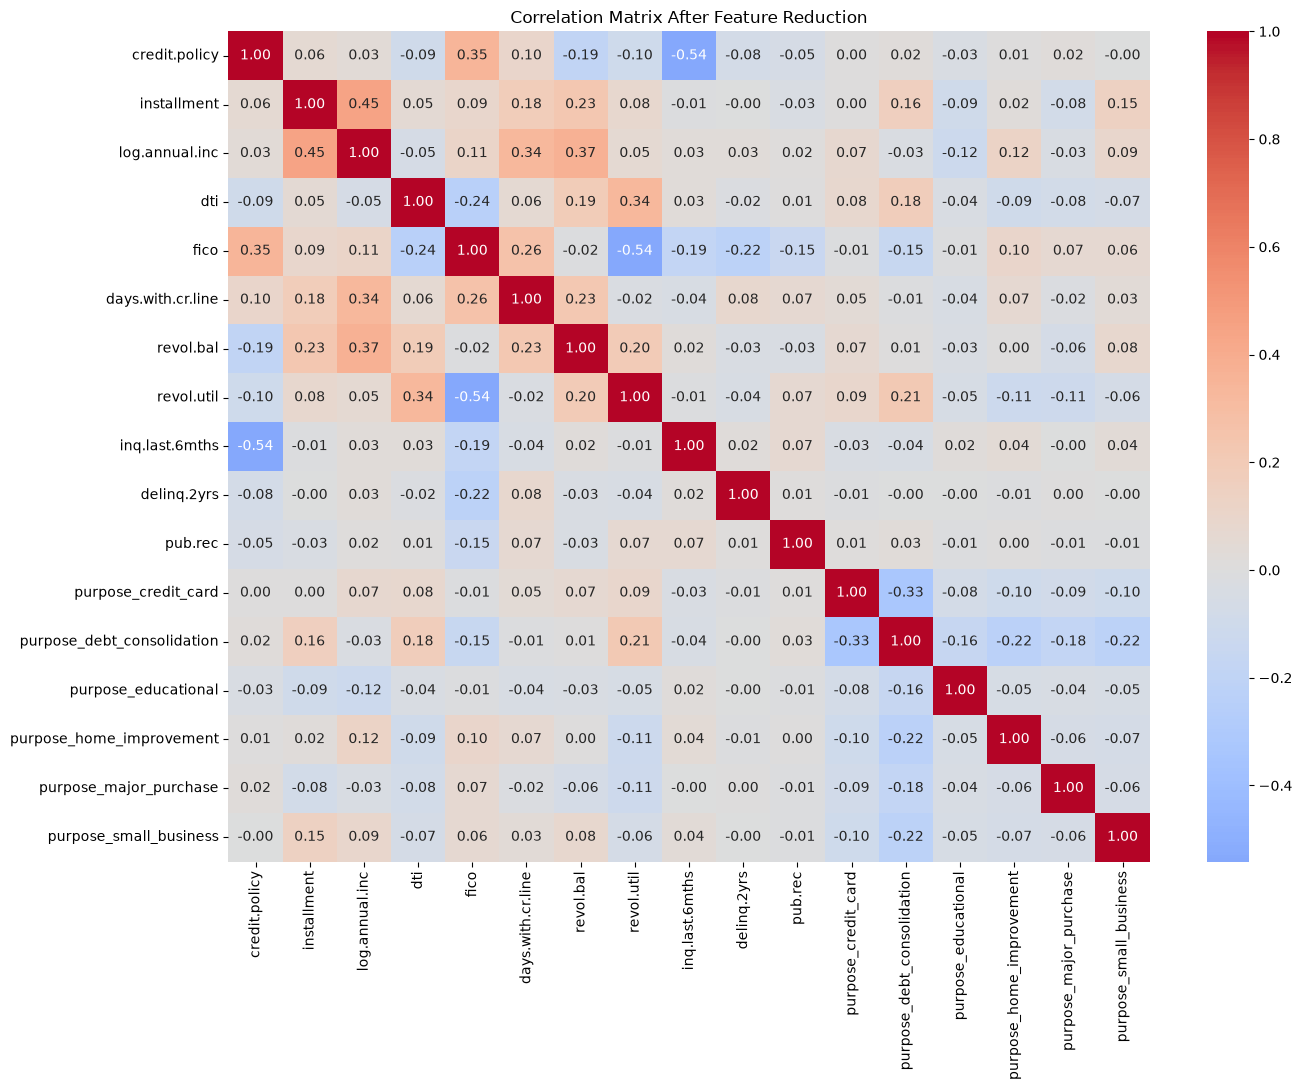

In [45]:
# ------------------------------------------------------------
# 7. Final correlation matrix
# ------------------------------------------------------------

plt.figure(figsize=(14, 11))

sns.heatmap(
    reduced_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix After Feature Reduction")
plt.tight_layout()
plt.show()

In [46]:
# ------------------------------------------------------------
# 8. Create final modeling dataset
# ------------------------------------------------------------

model_df = X_reduced.copy()

model_df[TARGET] = y

print("=" * 60)
print("FINAL MODELING DATASET")
print("=" * 60)

print("Shape:", model_df.shape)

print("\nColumns:")
print(model_df.columns.tolist())

print("\nFirst 5 rows:")
display(model_df.head())

FINAL MODELING DATASET
Shape: (9578, 18)

Columns:
['credit.policy', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business', 'not.fully.paid']

First 5 rows:


,credit.policy,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business,not.fully.paid
0,1,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,1,0,0,0,0,0
1,1,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,1,0,0,0,0,0,0
2,1,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,1,0,0,0,0,0
3,1,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,1,0,0,0,0,0
4,1,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,1,0,0,0,0,0,0


In [47]:
# ------------------------------------------------------------
# 9. Verify target variable
# ------------------------------------------------------------

print("Target distribution in final dataset:")
display(model_df[TARGET].value_counts())

print("\nTarget proportions:")
display(
    model_df[TARGET]
    .value_counts(normalize=True)
    .round(4)
)

Target distribution in final dataset:


not.fully.paid
0    8045
1    1533
Name: count, dtype: int64


Target proportions:


not.fully.paid
0    0.8399
1    0.1601
Name: proportion, dtype: float64

In [48]:
# ------------------------------------------------------------
# 10. Phase 3 completion summary
# ------------------------------------------------------------
print(f"Original features       : {X.shape[1]}")
print(f"Features removed        : {len(features_to_drop)}")
print(f"Final features          : {X_reduced.shape[1]}")
print(f"Removed feature(s)      : {features_to_drop}")
print(f"Final dataset shape     : {model_df.shape}")

Original features       : 18
Features removed        : 1
Final features          : 17
Removed feature(s)      : ['int.rate']
Final dataset shape     : (9578, 18)


In [49]:
# ============================================================
# PHASE 4 — MODEL DATA PREPARATION
# Lending Club Loan Data Analysis
# ============================================================

# ------------------------------------------------------------
# 1. Separate features and target
# ------------------------------------------------------------

X = model_df.drop(columns=[TARGET])
y = model_df[TARGET]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Features shape: (9578, 17)
Target shape: (9578,)

Features:
['credit.policy', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_educational', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_small_business']


In [50]:
# ------------------------------------------------------------
# 2. Split data into training and testing sets
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("TRAIN-TEST SPLIT")
print("=" * 60)

print("Training features :", X_train.shape)
print("Testing features  :", X_test.shape)

print("Training target   :", y_train.shape)
print("Testing target    :", y_test.shape)

TRAIN-TEST SPLIT
Training features : (7662, 17)
Testing features  : (1916, 17)
Training target   : (7662,)
Testing target    : (1916,)


In [51]:
# ------------------------------------------------------------
# 4. Feature scaling
# ------------------------------------------------------------

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [53]:
# ------------------------------------------------------------
# 5. Convert scaled arrays back to DataFrames
# ------------------------------------------------------------

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:")
display(X_train_scaled.head())

Scaled training data:


,credit.policy,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
6381,0.491542,1.109194,0.696658,0.012171,-0.629324,0.275685,-0.007634,0.951523,-0.262631,1.591971,-0.238688,2.584058,-0.834196,-0.194033,-0.261668,-0.219765,-0.265913
7589,0.491542,-0.795226,0.174696,0.017975,0.689102,0.234302,-0.156335,-0.150797,-0.726077,-0.302667,-0.238688,2.584058,-0.834196,-0.194033,-0.261668,-0.219765,-0.265913
465,0.491542,-0.889878,-0.252212,-0.101001,0.161732,0.699294,0.078160,-0.339668,-0.726077,1.591971,-0.238688,-0.386988,1.198759,-0.194033,-0.261668,-0.219765,-0.265913
5343,0.491542,0.096296,1.097154,0.506940,-0.629324,-0.493588,-0.456364,0.086150,-0.262631,-0.302667,-0.238688,-0.386988,-0.834196,-0.194033,-0.261668,-0.219765,-0.265913
8016,-2.034412,0.576044,1.172312,-0.333151,-1.288536,-1.555593,-0.503080,-1.613689,1.127705,-0.302667,-0.238688,-0.386988,1.198759,-0.194033,-0.261668,-0.219765,-0.265913


In [54]:
# ------------------------------------------------------------
# 6. Verify scaling
# ------------------------------------------------------------

print("=" * 60)
print("SCALING VERIFICATION")
print("=" * 60)

scaling_check = pd.DataFrame({
    "Mean": X_train_scaled.mean(),
    "Std": X_train_scaled.std()
})

display(scaling_check.round(3))

SCALING VERIFICATION


,Mean,Std
credit.policy,0.0,1.0
installment,-0.0,1.0
log.annual.inc,-0.0,1.0
dti,0.0,1.0
fico,-0.0,1.0
days.with.cr.line,0.0,1.0
revol.bal,0.0,1.0
revol.util,0.0,1.0
inq.last.6mths,-0.0,1.0
delinq.2yrs,-0.0,1.0


In [55]:
# ------------------------------------------------------------
# 7. Calculate class weights
# ------------------------------------------------------------

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, class_weights_array)
)

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

for class_label, weight in class_weights.items():
    print(f"Class {class_label}: {weight:.4f}")

CLASS WEIGHTS
Class 0: 0.5952
Class 1: 3.1248


In [56]:
# ------------------------------------------------------------
# 8. Final model-preparation verification
# ------------------------------------------------------------

print("=" * 60)
print("MODEL DATA PREPARATION SUMMARY")
print("=" * 60)

print(f"Original dataset       : {model_df.shape}")
print(f"Training data          : {X_train_scaled.shape}")
print(f"Testing data           : {X_test_scaled.shape}")

print(f"\nTraining samples       : {len(X_train_scaled)}")
print(f"Testing samples        : {len(X_test_scaled)}")

print(f"\nNumber of input features: {X_train_scaled.shape[1]}")
print(f"Target variable         : {TARGET}")

print("\nClass weights:")
print(class_weights)

MODEL DATA PREPARATION SUMMARY
Original dataset       : (9578, 18)
Training data          : (7662, 17)
Testing data           : (1916, 17)

Training samples       : 7662
Testing samples        : 1916

Number of input features: 17
Target variable         : not.fully.paid

Class weights:
{np.int64(0): np.float64(0.5952454940957116), np.int64(1): np.float64(3.124796084828711)}


In [57]:
# ============================================================
# PHASE 5 — DEEP LEARNING MODEL
# Lending Club Loan Data Analysis
# ============================================================

# ------------------------------------------------------------
# 1. Import TensorFlow and Keras
# ------------------------------------------------------------

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1


In [58]:
# ------------------------------------------------------------
# 2. Set random seeds
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

print("Random seeds set successfully.")

Random seeds set successfully.


In [59]:
# ------------------------------------------------------------
# 3. Determine input dimensions
# ------------------------------------------------------------

input_features = X_train_scaled.shape[1]

print("Number of input features:", input_features)
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

Number of input features: 17
Training samples: 7662
Testing samples: 1916


In [60]:
# ------------------------------------------------------------
# 4. Build the deep learning model
# ------------------------------------------------------------

model = keras.Sequential([
    
    layers.Input(shape=(input_features,)),
    
    layers.Dense(32, activation="relu"),
    
    layers.Dropout(0.2),
    
    layers.Dense(16, activation="relu"),
    
    layers.Dense(1, activation="sigmoid")
])

print("Deep learning model created.")

Deep learning model created.


In [61]:
# ------------------------------------------------------------
# 5. Display model architecture
# ------------------------------------------------------------

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
# ------------------------------------------------------------
# 6. Compile the model
# ------------------------------------------------------------

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [63]:
# ------------------------------------------------------------
# 7. Early stopping
# ------------------------------------------------------------

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Early stopping configured.")

Early stopping configured.


In [64]:
# ------------------------------------------------------------
# 8. Train the deep learning model
# ------------------------------------------------------------

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5443 - auc: 0.6029 - loss: 0.6824 - precision: 0.2011 - recall: 0.6115 - val_accuracy: 0.6517 - val_auc: 0.6553 - val_loss: 0.6451 - val_precision: 0.2316 - val_recall: 0.5489
Epoch 2/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6153 - auc: 0.6530 - loss: 0.6578 - precision: 0.2289 - recall: 0.5822 - val_accuracy: 0.6660 - val_auc: 0.6650 - val_loss: 0.6190 - val_precision: 0.2382 - val_recall: 0.5362
Epoch 3/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6154 - auc: 0.6665 - loss: 0.6504 - precision: 0.2349 - recall: 0.6105 - val_accuracy: 0.6464 - val_auc: 0.6692 - val_loss: 0.6260 - val_precision: 0.2283 - val_recall: 0.5489
Epoch 4/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5991 - auc: 0.6671 - loss: 0.6510 - precision: 0.2313 - recall: 0.6367 - val_accuracy: 0.6491 - val_auc: 0.6739 - val_loss: 0.6209 - val_precision: 0.2270 - val_recall: 0.5362
Epoch 5/50
192/192 ━━━━━━━━━━━━━

In [65]:
# ------------------------------------------------------------
# 9. Training history
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)

print("Training history:")
display(history_df)

Training history:


,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall
0,0.544298,0.602929,0.682431,0.201062,0.611504,0.651663,0.655332,0.645102,0.231598,0.548936
1,0.615272,0.653000,0.657845,0.228877,0.582240,0.666014,0.665036,0.619011,0.238185,0.536170
2,0.615435,0.666486,0.650362,0.234860,0.610494,0.646445,0.669164,0.625952,0.228319,0.548936
3,0.599119,0.667108,0.650988,0.231305,0.636731,0.649054,0.673880,0.620864,0.227027,0.536170
4,0.612498,0.678311,0.644627,0.238868,0.638749,0.637312,0.675479,0.622498,0.223752,0.553191
5,0.614293,0.679542,0.642951,0.240650,0.642785,0.641879,0.676765,0.622133,0.230241,0.570213
6,0.618861,0.685382,0.640510,0.245747,0.655903,0.653620,0.675989,0.615347,0.232852,0.548936
7,0.621145,0.685966,0.638157,0.244726,0.643794,0.656230,0.675724,0.612682,0.233577,0.544681
8,0.621309,0.688379,0.636571,0.244624,0.642785,0.654925,0.676284,0.614988,0.235612,0.557447
9,0.622777,0.685584,0.638602,0.245079,0.640767,0.664057,0.676396,0.609081,0.232824,0.519149


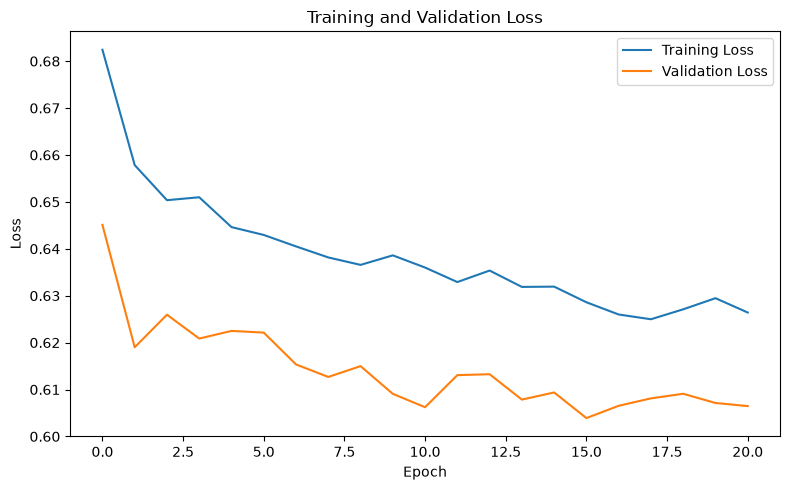

In [66]:
# ------------------------------------------------------------
# 10. Plot training and validation loss
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

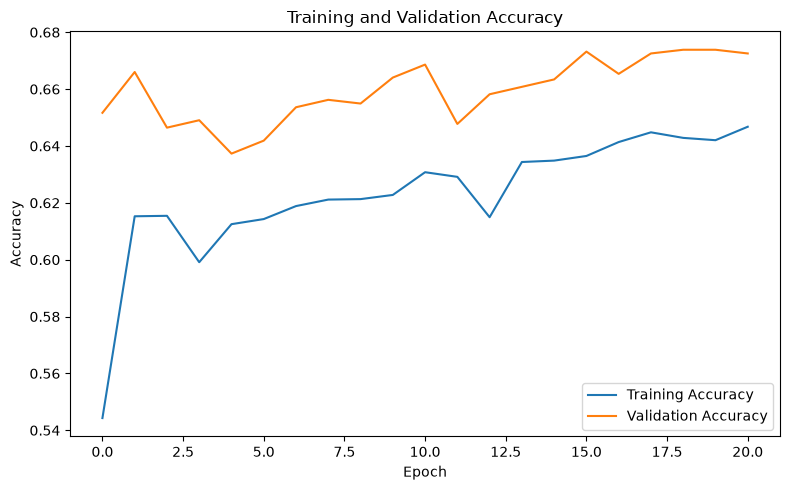

In [67]:
# ------------------------------------------------------------
# 11. Plot training and validation accuracy
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [68]:
# ------------------------------------------------------------
# 12. Training summary
# ------------------------------------------------------------

epochs_completed = len(history.history["loss"])

best_epoch = (
    np.argmin(history.history["val_loss"]) + 1
)

best_val_loss = min(history.history["val_loss"])

print("=" * 60)
print("TRAINING SUMMARY")
print("=" * 60)

print(f"Epochs completed : {epochs_completed}")
print(f"Best epoch       : {best_epoch}")
print(f"Best val loss    : {best_val_loss:.4f}")

TRAINING SUMMARY
Epochs completed : 21
Best epoch       : 16
Best val loss    : 0.6039


In [69]:
# ============================================================
# PHASE 6 — FINAL MODEL EVALUATION
# Lending Club Loan Data Analysis
# ============================================================

# ------------------------------------------------------------
# 1. Evaluate the model on the test dataset
# ------------------------------------------------------------

test_results = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("=" * 60)
print("TEST SET EVALUATION")
print("=" * 60)

for metric_name, metric_value in zip(model.metrics_names, test_results):
    print(f"{metric_name:<12}: {metric_value:.4f}")

TEST SET EVALUATION
loss        : 0.6020
compile_metrics: 0.6634


In [70]:
# ------------------------------------------------------------
# 2. Generate predictions
# ------------------------------------------------------------

y_pred_probability = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
y_pred = (y_pred_probability >= 0.50).astype(int)

print("Predictions generated successfully.")

print("\nFirst 10 predicted probabilities:")
print(y_pred_probability[:10])

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

Predictions generated successfully.

First 10 predicted probabilities:
[0.64312893 0.35768896 0.448906   0.467774   0.5390911  0.8191362
 0.57817113 0.47337025 0.5267782  0.65933824]

First 10 predicted classes:
[1 0 0 0 1 1 1 0 1 1]


In [71]:
# ------------------------------------------------------------
# 3. Calculate evaluation metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test,
    y_pred_probability
)

evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "AUC"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_auc
    ]
})

evaluation_results["Score"] = evaluation_results["Score"].round(4)

print("=" * 60)
print("FINAL TEST METRICS")
print("=" * 60)

display(evaluation_results)

FINAL TEST METRICS


,Metric,Score
0,Accuracy,0.6634
1,Precision,0.2455
2,Recall,0.5309
3,AUC,0.6867


In [72]:
# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No Default (0)", "Actual Default (1)"],
    columns=["Predicted No Default (0)", "Predicted Default (1)"]
)

display(cm_df)

CONFUSION MATRIX


,Predicted No Default (0),Predicted Default (1)
Actual No Default (0),1108,501
Actual Default (1),144,163


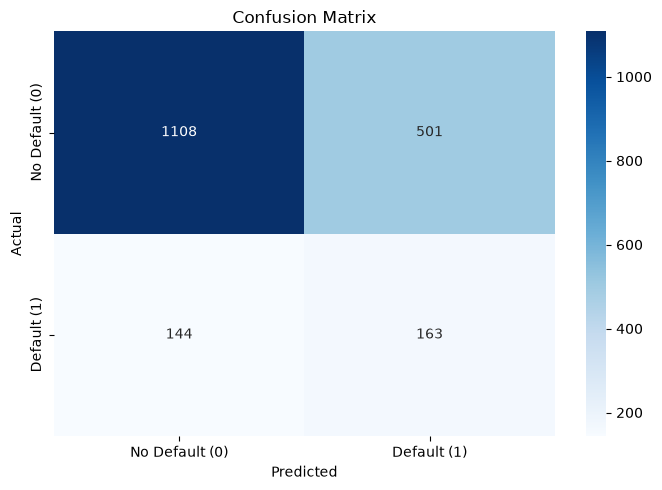

In [73]:
# ------------------------------------------------------------
# 5. Confusion matrix visualization
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default (0)", "Default (1)"],
    yticklabels=["No Default (0)", "Default (1)"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [74]:
# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

from sklearn.metrics import classification_report

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Default (0)",
            "Default (1)"
        ],
        zero_division=0
    )
)

CLASSIFICATION REPORT
                precision    recall  f1-score   support

No Default (0)       0.88      0.69      0.77      1609
   Default (1)       0.25      0.53      0.34       307

      accuracy                           0.66      1916
     macro avg       0.57      0.61      0.56      1916
  weighted avg       0.78      0.66      0.70      1916



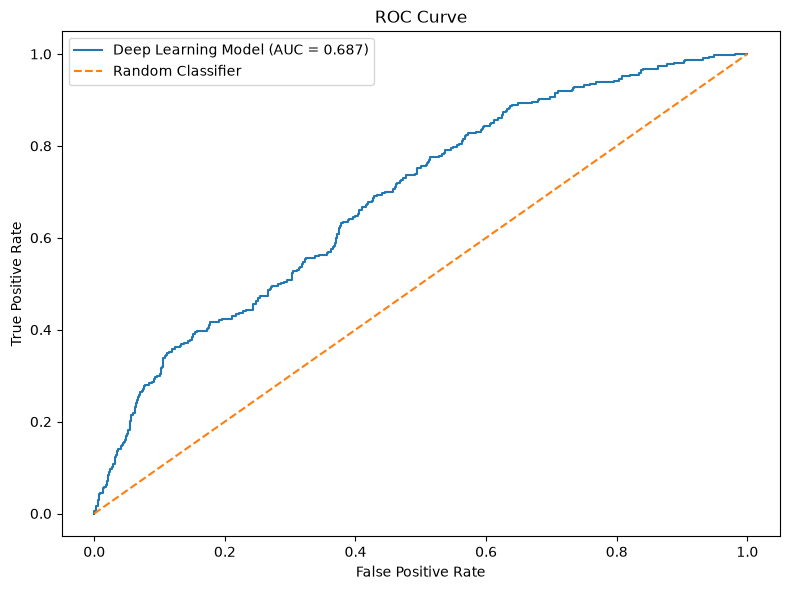

In [75]:
# ------------------------------------------------------------
# 7. ROC curve
# ------------------------------------------------------------

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Deep Learning Model (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()

In [76]:
# ------------------------------------------------------------
# 8. Prediction summary
# ------------------------------------------------------------

prediction_summary = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Default Probability": y_pred_probability
})

print("=" * 60)
print("PREDICTION SUMMARY")
print("=" * 60)

display(prediction_summary.head(10))

print("\nActual class distribution:")
display(y_test.value_counts())

print("\nPredicted class distribution:")
display(pd.Series(y_pred).value_counts())

PREDICTION SUMMARY


,Actual,Predicted,Default Probability
0,0,1,0.643129
1,0,0,0.357689
2,0,0,0.448906
3,0,0,0.467774
4,1,1,0.539091
5,0,1,0.819136
6,0,1,0.578171
7,1,0,0.473370
8,0,1,0.526778
9,0,1,0.659338



Actual class distribution:


not.fully.paid
0    1609
1     307
Name: count, dtype: int64


Predicted class distribution:


0    1252
1     664
Name: count, dtype: int64

In [78]:
# ------------------------------------------------------------
# Save the trained Keras model
# ------------------------------------------------------------

model.save("lending_club_default_model.keras")

print("Final model saved as:")
print("lending_club_default_model.keras")

Final model saved as:
lending_club_default_model.keras


In [79]:
# ------------------------------------------------------------
# Save the feature scaler
# ------------------------------------------------------------

import joblib

joblib.dump(
    scaler,
    "lending_club_scaler.pkl"
)

print("Scaler saved as:")
print("lending_club_scaler.pkl")

Scaler saved as:
lending_club_scaler.pkl


In [80]:
# ------------------------------------------------------------
# Save final feature names
# ------------------------------------------------------------

final_features = X_train.columns.tolist()

with open("lending_club_features.txt", "w") as file:
    for feature in final_features:
        file.write(feature + "\n")

print("Final feature list saved as:")
print("lending_club_features.txt")

Final feature list saved as:
lending_club_features.txt
